<a href="https://colab.research.google.com/github/abhimanyu-05-2006/YuvaIntern-ML-Engineer-Tasks/blob/main/Task_4_Tool_Mastery_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
from scipy import stats
import time

# 1. High-Performance Matrix Operations & BLAS Vectorization Benchmark
np.random.seed(42)
matrix_dimension = (1500, 1500)
A = np.random.normal(loc=10.0, scale=2.5, size=matrix_dimension)
B = np.random.normal(loc=5.0, scale=1.2, size=matrix_dimension)

# Benchmark Matrix Multiplication Execution Time
t_start = time.perf_counter()
C_matrix = np.dot(A, B)
execution_duration_ms = (time.perf_counter() - t_start) * 1000

# 2. Advanced SciPy Statistical Profiling & Hypothesis Testing
sample_telemetry = np.random.gamma(shape=2.0, scale=15.0, size=1000)
sample_mean = np.mean(sample_telemetry)
sample_median = np.median(sample_telemetry)
sample_std = np.std(sample_telemetry, ddof=1)

skewness_val = stats.skew(sample_telemetry)
kurtosis_val = stats.kurtosis(sample_telemetry)
t_stat, p_val = stats.ttest_1samp(sample_telemetry, popmean=30.0)

print(f"[NUMPY BENCHMARK] 1500x1500 Matrix Dot Product Execution Time: {execution_duration_ms:.4f} ms")
print(f"[SCIPY STATS] Empirical Mean: {sample_mean:.2f} | Median: {sample_median:.2f} | Std Dev: {sample_std:.2f}")
print(f"[DISTRIBUTION SHAPE] Skewness: {skewness_val:.4f} | Excess Kurtosis: {kurtosis_val:.4f}")
print(f"[HYPOTHESIS TEST] One-sample t-test -> t-stat: {t_stat:.4f}, p-value: {p_val:.6f}")

[NUMPY BENCHMARK] 1500x1500 Matrix Dot Product Execution Time: 349.7835 ms
[SCIPY STATS] Empirical Mean: 29.68 | Median: 25.32 | Std Dev: 21.03
[DISTRIBUTION SHAPE] Skewness: 1.5370 | Excess Kurtosis: 3.4697
[HYPOTHESIS TEST] One-sample t-test -> t-stat: -0.4776, p-value: 0.633017


In [2]:
import pandas as pd

# Load structured retail and telemetry dataset (800 rows)
np.random.seed(2026)
n_rows = 800

df_raw = pd.DataFrame({
    'transaction_id': [f"TXN_{i:06d}" for i in range(1, n_rows + 1)],
    'fulfillment_center': np.random.choice(['Center_North', 'Center_South', 'Center_East', 'Center_West'], size=n_rows),
    'product_category': np.random.choice(['Electronics', 'Cloud_Compute', 'Hardware_SaaS', 'Security'], size=n_rows),
    'unit_cost_usd': np.round(np.random.uniform(50.0, 1200.0, size=n_rows), 2),
    'units_sold': np.random.randint(1, 15, size=n_rows),
    'discount_applied_pct': np.random.choice([0.0, 0.05, 0.10, 0.15, 0.20, 0.25], size=n_rows),
    'client_satisfaction_score': np.random.choice([1, 2, 3, 4, 5], size=n_rows, p=[0.05, 0.10, 0.25, 0.40, 0.20])
})

# Advanced Method Chaining Pipeline for Financial Feature Engineering
processed_retail_df = (
    df_raw
    .assign(gross_revenue=lambda df: df['unit_cost_usd'] * df['units_sold'])
    .assign(net_revenue=lambda df: df['gross_revenue'] * (1 - df['discount_applied_pct']))
    .assign(profit_margin_proxy=lambda df: df['net_revenue'] / (df['units_sold'] + 1))
    .query('net_revenue > 150.0')
)

# Multi-level Pivot Summary
pivot_financial_summary = processed_retail_df.pivot_table(
    index=['fulfillment_center', 'product_category'],
    values=['gross_revenue', 'net_revenue', 'client_satisfaction_score'],
    aggfunc={
        'gross_revenue': 'sum',
        'net_revenue': 'sum',
        'client_satisfaction_score': 'mean'
    }
).round(2)

print(f"[PANDAS PIPELINE] Filtered Rows Retained: {len(processed_retail_df)} out of {n_rows}")
print("\n--- Multi-Level Pivot Financial Summary ---")
print(pivot_financial_summary.head(10))

[PANDAS PIPELINE] Filtered Rows Retained: 791 out of 800

--- Multi-Level Pivot Financial Summary ---
                                     client_satisfaction_score  gross_revenue  \
fulfillment_center product_category                                             
Center_East        Cloud_Compute                          3.69      211840.85   
                   Electronics                            3.65      237882.21   
                   Hardware_SaaS                          3.68      197925.03   
                   Security                               3.78      192724.44   
Center_North       Cloud_Compute                          3.72      307848.38   
                   Electronics                            3.50      178027.21   
                   Hardware_SaaS                          3.53      261787.81   
                   Security                               3.56      295435.21   
Center_South       Cloud_Compute                          3.76      264384.49   
       

[MODEL BENCHMARK] Gradient Boosting Test Accuracy: 58.08%
[MODEL BENCHMARK] ROC-AUC Score: 0.5319


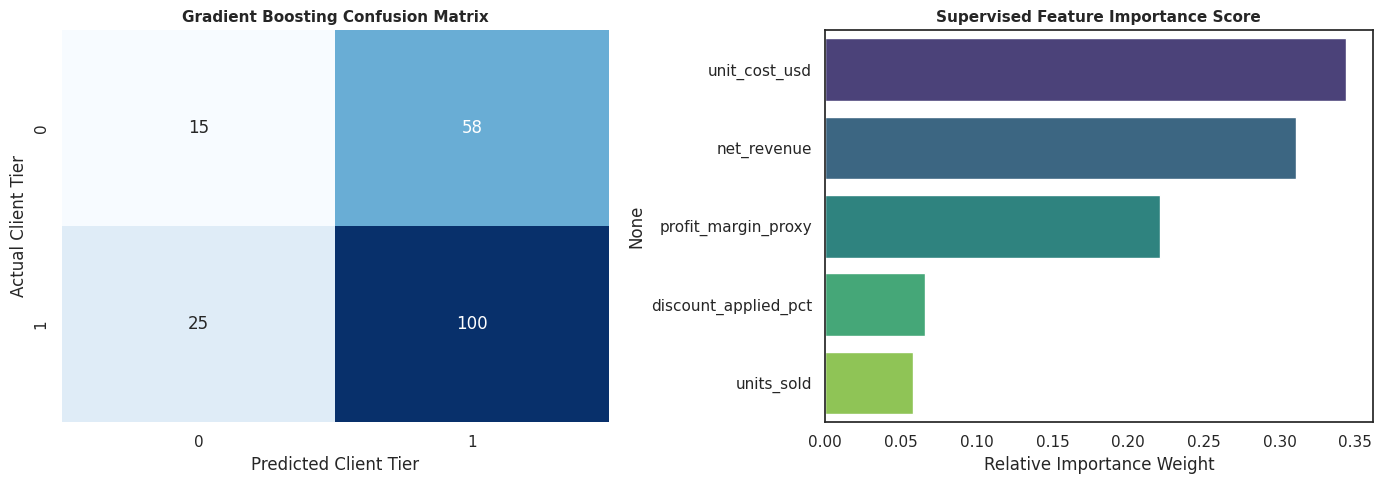


--- Detailed Classification Report ---
                          precision    recall  f1-score   support

Low/Mid Satisfaction (0)       0.38      0.21      0.27        73
   High Satisfaction (1)       0.63      0.80      0.71       125

                accuracy                           0.58       198
               macro avg       0.50      0.50      0.49       198
            weighted avg       0.54      0.58      0.54       198



In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

# Feature Matrix & Binary Target Construction (1 = High Satisfaction [4 or 5], 0 = Low/Mid [1, 2, 3])
X = processed_retail_df[['unit_cost_usd', 'units_sold', 'discount_applied_pct', 'net_revenue', 'profit_margin_proxy']]
y = (processed_retail_df['client_satisfaction_score'] >= 4).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Feature Standardization Pipeline
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Gradient Boosting Supervised Model Training
gb_classifier = GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=4, random_state=42)
gb_classifier.fit(X_train_scaled, y_train)

y_pred = gb_classifier.predict(X_test_scaled)
y_probabilities = gb_classifier.predict_proba(X_test_scaled)[:, 1]

test_accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probabilities)

print(f"[MODEL BENCHMARK] Gradient Boosting Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"[MODEL BENCHMARK] ROC-AUC Score: {roc_auc:.4f}")

# Diagnostic Visualization Suite
sns.set_theme(style="white")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(ax=axes[0], data=cm, annot=True, fmt='d', cmap="Blues", cbar=False)
axes[0].set_title("Gradient Boosting Confusion Matrix", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Predicted Client Tier")
axes[0].set_ylabel("Actual Client Tier")

# Plot 2: Feature Importance Bar Plot
feature_importances = pd.Series(gb_classifier.feature_importances_, index=X.columns).sort_values(ascending=False)
sns.barplot(ax=axes[1], x=feature_importances.values, y=feature_importances.index, hue=feature_importances.index, palette="viridis", legend=False)
axes[1].set_title("Supervised Feature Importance Score", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Relative Importance Weight")

plt.tight_layout()
plt.show()

print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Low/Mid Satisfaction (0)', 'High Satisfaction (1)']))